# 04. Нормальные ткани как фоновый класс: помогает ли это на метастазах?

**Проблема из ноутбука 03.** На MET500 модель часто называет метастаз по органу, где его нашли: рак груди в печени становится «раком печени». Модель читает окружающую нормальную ткань.

**Идея.** Добавить в обучение нормальные ткани из GTEx (26 органов, ~3 300 образцов здоровых доноров) как отдельные классы `NORMAL_Liver`, `NORMAL_Lung` и т. д. Тогда у «печёночного» сигнала появляется свой класс, куда он может уйти, вместо того чтобы голосовать за рак печени. При предсказании нормальные классы отбрасываются, и вероятности пересчитываются только по 32 типам рака.

**Дизайн эксперимента (зафиксирован до просмотра результатов):**
- две модели с одинаковыми генами и настройками: «только опухоли» и «опухоли + нормальные ткани»;
- гены: только те, что есть и в TCGA, и в GTEx (15 629). Иначе ген, отсутствующий в GTEx, был бы там заполнен константой, и «константа» стала бы подсказкой «это норма» — та же ловушка, что с платформенными пропусками;
- образцы GTEx нормализуются к TCGA так же, как внешние данные;
- MET500 используется только для итогового сравнения, ничего под него не подбирается.

Расчёт: `src/background.py`.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display

R = "../results"
bg = json.load(open(f"{R}/background.json"))
print(f"GTEx: {bg['gtex_samples']} образцов, {bg['gtex_tissues']} тканей; общих генов: {bg['genes']}")
print(f"нормальная ткань отложенных доноров GTEx распознана верно: {bg['normal_tissue_accuracy_heldout']:.1%}")

GTEx: 3339 образцов, 26 тканей; общих генов: 15629
нормальная ткань отложенных доноров GTEx распознана верно: 99.5%


Модель уверенно различает нормальные ткани (99.5% на донорах, которых она не видела), так что сами фоновые классы выучены хорошо. Вопрос в том, помогают ли они опухолям.

In [2]:
rows = []
for name, r in bg["models"].items():
    rows.append({"модель": "только опухоли" if name == "tumours_only" else "+ нормальные ткани GTEx",
                 "тест TCGA": round(r["tcga_test"]["accuracy"], 3),
                 "CPTAC-3": round(r["cptac3"]["accuracy"], 3),
                 "MET500": round(r["met500"]["accuracy"], 3),
                 "MET500 топ-3": round(r["met500"]["top3_accuracy"], 3),
                 "метастазы в печени → LIHC": r["met500_liver_called_LIHC"]})
pd.DataFrame(rows)

,модель,тест TCGA,CPTAC-3,MET500,MET500 топ-3,метастазы в печени → LIHC
0,только опухоли,0.970,0.908,0.664,0.817,41
1,+ нормальные ткани GTEx,0.972,0.926,0.629,0.801,41


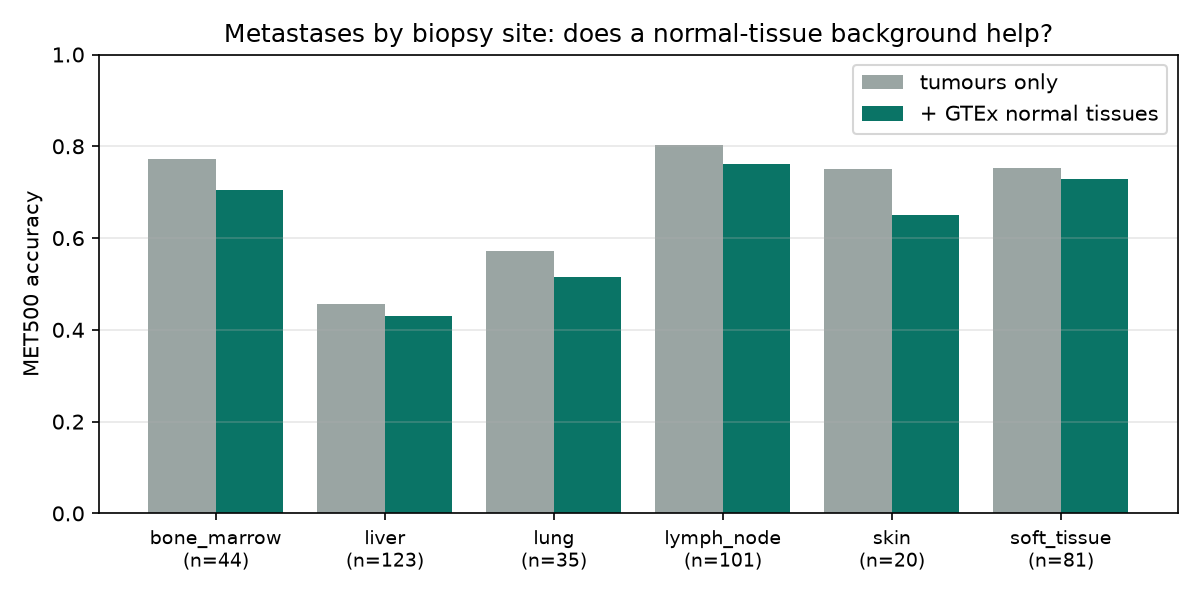

{'share': 0.08466819221967964,
 'by_biopsy_site': {'liver -> NORMAL_Liver': 7,
  'bone_marrow -> NORMAL_Blood': 5,
  'lung -> NORMAL_Lung': 3}}

In [3]:
display(Image(f"{R}/figures/background_met500.png", width=800))
bg["models"]["with_normal_background"]["met500_top_guess_normal"]

## Результат: отрицательный, и это полезно

- **На MET500 точность не выросла, а упала: 66.4% → 62.9%.** Метастазов в печени, названных раком печени, ровно столько же — 41. Падение есть во всех органах биопсии.
- На первичных опухолях стало чуть лучше: CPTAC-3 90.8% → 92.6%, тест TCGA без изменений. То есть модель не сломалась, просто идея не решает проблему метастазов.
- Только 8% метастазов модель целиком назвала бы нормальной тканью (в основном печень → `NORMAL_Liver`), так что «сигнал органа» почти никогда не перевешивает опухоль.

### Почему не сработало

У логистической регрессии с несколькими классами есть свойство: отношение вероятностей двух классов зависит только от них двоих:

$$\frac{P(\text{LIHC})}{P(\text{BRCA})} = e^{(w_\text{LIHC} - w_\text{BRCA}) \cdot x}$$

Наличие класса `NORMAL_Liver` в этой формуле не участвует. Он меняет только то, как обучаются веса, но при обучении модель по-прежнему видит: у LIHC печёночные гены высокие, у BRCA низкие. Значит, в сравнении «LIHC против BRCA» печёночные гены остаются сильным доводом за LIHC. А метастаз рака груди в печени — это **смесь** груди и печени, и печёночные гены в нём высокие. Фоновый класс учит модель отличать рак печени от *нормальной* печени, но не учит её, что в смеси печёночный сигнал надо игнорировать.

### Что должно сработать лучше

Показать модели такие смеси при обучении: **аугментация смесями**. Берём опухоль TCGA (например, BRCA), смешиваем её профиль с нормальной тканью другого органа из GTEx (например, 30% печени) и оставляем метку BRCA. Тогда модель прямо учится, что печёночный сигнал не меняет ответ. Это следующий логичный эксперимент; проверять его нужно так же — дизайн фиксируется заранее, MET500 только для итоговой оценки.

## Итог

| Вопрос | Ответ |
|---|---|
| Помогают ли нормальные ткани как отдельные классы на метастазах? | Нет: MET500 66.4% → 62.9%, метастазы в печени → LIHC: 41 → 41 |
| Портят ли они модель? | Нет: TCGA 97.0% → 97.2%, CPTAC-3 90.8% → 92.6% |
| Почему? | В логистической регрессии сравнение двух опухолей не зависит от фонового класса; нужны обучающие смеси, а не отдельный класс |

Отрицательный результат, полученный по заранее зафиксированному плану, — тоже результат: он отсекает простое решение и указывает на правильное.